# ส่วนที่ 1: การจัดการข้อมูลทางการเงินด้วย Python
โค้ดอ้างอิงสำหรับรายงานส่วนที่ 1 ใช้หุ้นตัวแทนของกลุ่ม **KBANK, CPALL, OR, AOT** ข้อมูลย้อนหลัง 1 ปีจาก yfinance

- 1.1 การใช้ NumPy สำหรับการจัดการข้อมูล
- 1.2 การใช้ Pandas สำหรับการจัดการข้อมูล
- 1.3 การใช้ matplotlib / seaborn / mplfinance

### 0. Setup

In [1]:
# !pip install yfinance pandas numpy matplotlib seaborn scipy mplfinance   # รันครั้งแรกหากยังไม่มีไลบรารี
import warnings                         # ไว้ปิด warning ที่ไม่จำเป็น
warnings.filterwarnings("ignore")       # ปิด warning ไม่ให้รกตอนรัน

import numpy as np                      # คำนวณตัวเลข / array / matrix
import pandas as pd                     # จัดการข้อมูลแบบตาราง
import matplotlib.pyplot as plt         # วาดกราฟพื้นฐาน
import seaborn as sns                   # วาดกราฟเชิงสถิติ
import yfinance as yf                   # ดึงข้อมูลหุ้นจาก Yahoo Finance

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # แสดงทศนิยม 4 ตำแหน่ง
pd.set_option("display.width", 160)                            # ตารางกว้างขึ้น ไม่ตัดคอลัมน์
sns.set_theme(style="whitegrid", palette="deep")               # ธีมกราฟพื้นขาวมีกริด
plt.rcParams["figure.dpi"] = 110                               # กราฟคมขึ้น

TICKERS = ["KBANK", "CPALL", "OR", "AOT"]                      # หุ้นที่กลุ่มเลือก (กลุ่มละ 1 ตัว)
SECTOR_OF = {"KBANK": "Finance & Banking", "CPALL": "Consumer & Retail",
             "OR": "Energy & Utilities", "AOT": "Transportation"}   # หุ้นแต่ละตัวอยู่กลุ่มไหน
SYMBOLS = [f"{t}.BK" for t in TICKERS]                         # หุ้นไทยใน yfinance ต้องเติม .BK
RF = 0.02                                                      # risk-free rate 2% ต่อปี (พันธบัตรรัฐบาลไทย)
TRADING_DAYS = 252                                             # จำนวนวันทำการต่อปี

import mplfinance as mpf                # วาดกราฟแท่งเทียน

### ดึงข้อมูลจาก yfinance (ราคาหุ้น, งบการเงิน, อัตราส่วนทางการเงิน)

In [2]:
# ดึงราคาย้อนหลัง 1 ปีของทั้ง 4 ตัว (OHLCV) auto_adjust=True คือปรับราคาตามปันผล/แตกพาร์แล้ว
raw = yf.download(SYMBOLS, period="1y", auto_adjust=True, progress=False)
raw = raw.dropna(how="all")                                        # ตัดวันที่ไม่มีข้อมูลเลยทิ้ง
close = raw["Close"].rename(columns=lambda c: c.replace(".BK", ""))[TICKERS]   # เฉพาะราคาปิด ตัด .BK ออก
volume = raw["Volume"].rename(columns=lambda c: c.replace(".BK", ""))[TICKERS] # ปริมาณการซื้อขาย
print("ช่วงข้อมูล:", close.index[0].date(), "ถึง", close.index[-1].date(), "| จำนวนวัน:", len(close))
close.head()     # ดู 5 แถวแรก

ช่วงข้อมูล: 2025-11-05 ถึง 2026-11-05 | จำนวนวัน: 242


Ticker,KBANK,CPALL,OR,AOT
Date,,,,
2025-11-05,169.4732,43.3681,13.8652,39.4000
2025-11-06,169.9375,43.3681,13.8652,39.6463
2025-11-07,167.1517,43.3681,13.5783,40.3850
2025-11-10,169.0089,43.8500,13.6739,41.1237
2025-11-11,168.0803,43.3681,13.5783,41.8625


In [3]:
# ข้อมูลพื้นฐาน + อัตราส่วนทางการเงินจาก .info
rows = []
for t in TICKERS:
    info = yf.Ticker(f"{t}.BK").info                     # dict ข้อมูลของหุ้นตัวนั้น
    rows.append({
        "Ticker": t,
        "Name": info.get("longName"),                    # ชื่อเต็มบริษัท
        "Sector": SECTOR_OF[t],                          # กลุ่มอุตสาหกรรม
        "Price": info.get("currentPrice"),               # ราคาล่าสุด
        "Market Cap (THB bn)": info.get("marketCap", np.nan) / 1e9,   # มูลค่าตลาด (พันล้านบาท)
        "EPS": info.get("trailingEps"),                  # กำไรต่อหุ้น
        "P/E": info.get("trailingPE"),                   # ราคาต่อกำไร
        "P/BV": info.get("priceToBook"),                 # ราคาต่อมูลค่าทางบัญชี
        "ROE": info.get("returnOnEquity"),               # ผลตอบแทนต่อส่วนผู้ถือหุ้น
        "Dividend Yield (%)": info.get("dividendYield"), # อัตราปันผลตอบแทน
    })
ratios = pd.DataFrame(rows).set_index("Ticker")          # แปลงเป็นตาราง
ratios

,Name,Sector,Price,Market Cap (THB bn),EPS,P/E,P/BV,ROE,Dividend Yield (%)
Ticker,,,,,,,,,
KBANK,Kasikornbank Public Company Limited,Finance & Banking,247.0000,585.2239,21.5600,11.4564,0.9969,0.0851,4.9200
CPALL,CP ALL Public Company Limited,Consumer & Retail,46.2500,412.1384,3.3600,13.7649,3.1405,0.1038,3.7500
OR,PTT Oil and Retail Business Public Company Lim...,Energy & Utilities,12.6000,151.2000,0.4400,28.6364,1.3742,0.0477,4.8000
AOT,Airports of Thailand Public Company Limited,Transportation,61.2500,874.9991,1.3100,46.7557,6.5222,0.1431,1.3400


In [4]:
# งบการเงิน: งบกำไรขาดทุน (financials) และงบแสดงฐานะการเงิน (balance_sheet) ของ KBANK เป็นตัวอย่าง
tk = yf.Ticker("KBANK.BK")
fin = tk.financials                                       # แถว = รายการบัญชี, คอลัมน์ = ปีงบ
bs = tk.balance_sheet
print("งบกำไรขาดทุน KBANK (บางรายการ, พันล้านบาท)")
display((fin.loc[["Total Revenue", "Net Income"]] / 1e9).round(2))           # รายได้และกำไรสุทธิย้อนหลัง
print("งบแสดงฐานะการเงิน KBANK (บางรายการ, พันล้านบาท)")
display((bs.loc[["Total Assets", "Stockholders Equity"]] / 1e9).round(2))   # สินทรัพย์และส่วนผู้ถือหุ้น

งบกำไรขาดทุน KBANK (บางรายการ, พันล้านบาท)


,2025-12-31,2024-12-31,2023-12-31,2022-12-31,2021-12-31
Total Revenue,207.4300,209.4700,204.8200,179.9800,NaN
Net Income,49.5600,49.6000,42.4100,35.7700,NaN


งบแสดงฐานะการเงิน KBANK (บางรายการ, พันล้านบาท)


,2025-12-31,2024-12-31,2023-12-31,2022-12-31
Total Assets,"4,558.6200","4,340.9500","4,263.8400","4,246.3700"
Stockholders Equity,581.1500,568.7300,532.9600,503.2700


---
## 1.1 การใช้ NumPy สำหรับการจัดการข้อมูล
NumPy ทำงานกับ array ได้เร็วกว่า list ของ Python มาก เพราะคำนวณแบบ vectorized (ทำทั้ง array ทีเดียว ไม่ต้องวน loop)

In [5]:
p = close["KBANK"].to_numpy()          # แปลงราคา KBANK เป็น NumPy array
print("ชนิดข้อมูล:", type(p), "| shape:", p.shape, "| dtype:", p.dtype)
print("ราคา 5 วันแรก:", p[:5])          # slicing เหมือน list
print("ราคาสูงสุด:", np.max(p), "| ต่ำสุด:", np.min(p), "| เฉลี่ย:", np.mean(p).round(2))
print("วันที่ราคาสูงสุดอยู่ลำดับที่:", np.argmax(p))   # index ของค่ามากสุด

ชนิดข้อมูล: <class 'numpy.ndarray'> | shape: (242,) | dtype: float64
ราคา 5 วันแรก: [169.47323608 169.93754578 167.15168762 169.00892639 168.08030701]
ราคาสูงสุด: nan | ต่ำสุด: nan | เฉลี่ย: nan
วันที่ราคาสูงสุดอยู่ลำดับที่: 241


In [6]:
# คำนวณผลตอบแทนด้วย NumPy ล้วน ๆ
simple_np = np.diff(p) / p[:-1]          # (P_t - P_t-1) / P_t-1  -> np.diff คือผลต่างทีละคู่
log_np = np.diff(np.log(p))              # ln(P_t) - ln(P_t-1) = ln(P_t / P_t-1)
print("Simple return 5 วันแรก:", simple_np[:5].round(4))
print("Log return 5 วันแรก   :", log_np[:5].round(4))
print("ผลตอบแทนเฉลี่ยต่อวัน :", simple_np.mean().round(5), "| SD ต่อวัน:", simple_np.std(ddof=1).round(5))   # ddof=1 = SD ตัวอย่าง
print("Volatility ต่อปี      :", (simple_np.std(ddof=1) * np.sqrt(TRADING_DAYS)).round(4))               # คูณ root 252

Simple return 5 วันแรก: [ 0.0027 -0.0164  0.0111 -0.0055  0.0028]
Log return 5 วันแรก   : [ 0.0027 -0.0165  0.011  -0.0055  0.0028]
ผลตอบแทนเฉลี่ยต่อวัน : nan | SD ต่อวัน: nan
Volatility ต่อปี      : nan


In [7]:
# การกรองข้อมูลด้วยเงื่อนไข (boolean mask) และ np.where
up_days = simple_np > 0                                  # True = วันที่ราคาขึ้น
print("จำนวนวันที่ราคาขึ้น:", up_days.sum(), "จาก", len(simple_np), "วัน")
print("ผลตอบแทนเฉลี่ยเฉพาะวันขึ้น:", simple_np[up_days].mean().round(4))
direction = np.where(simple_np > 0, "UP", np.where(simple_np < 0, "DOWN", "FLAT"))   # ติดป้ายขึ้น/ลง/ทรงตัว
print("ทิศทาง 10 วันแรก:", direction[:10])
print("Percentile ที่ 5 และ 95:", np.percentile(simple_np, [5, 95]).round(4))       # ใช้ต่อในเรื่อง VaR

จำนวนวันที่ราคาขึ้น: 115 จาก 241 วัน
ผลตอบแทนเฉลี่ยเฉพาะวันขึ้น: 0.0113
ทิศทาง 10 วันแรก: ['UP' 'DOWN' 'UP' 'DOWN' 'UP' 'UP' 'DOWN' 'UP' 'UP' 'DOWN']
Percentile ที่ 5 และ 95: [nan nan]


In [8]:
# Matrix operation: ผลตอบแทนพอร์ตด้วย dot product
R = close.pct_change().dropna().to_numpy()               # matrix ผลตอบแทน (วัน x หุ้น)
w = np.array([0.25, 0.25, 0.25, 0.25])                   # น้ำหนักพอร์ตเท่ากัน
port_ret = R @ w                                         # ผลตอบแทนพอร์ตรายวัน = R · w
cov = np.cov(R, rowvar=False) * TRADING_DAYS             # covariance matrix ต่อปี (rowvar=False เพราะหุ้นอยู่คอลัมน์)
port_vol = np.sqrt(w @ cov @ w)                          # ความเสี่ยงพอร์ต = sqrt(w' Σ w)
print("shape ของ R:", R.shape)
print("ผลตอบแทนพอร์ตต่อปี:", (port_ret.mean() * TRADING_DAYS).round(4), "| ความเสี่ยงต่อปี:", port_vol.round(4))
print("Covariance matrix:\n", cov.round(4))

shape ของ R: (241, 4)
ผลตอบแทนพอร์ตต่อปี: 0.2214 | ความเสี่ยงต่อปี: 0.1827
Covariance matrix:
 [[0.0412 0.0142 0.0126 0.0218]
 [0.0142 0.0599 0.0216 0.0256]
 [0.0126 0.0216 0.0824 0.0209]
 [0.0218 0.0256 0.0209 0.1171]]


In [9]:
# Random: สุ่มน้ำหนักพอร์ต 5 ชุด (พื้นฐานของ Monte Carlo ในส่วนที่ 3)
rng = np.random.default_rng(42)            # fix seed ให้ได้ผลเหมือนเดิมทุกครั้ง
rand_w = rng.random((5, 4))                # สุ่มเลข 0-1 ขนาด 5x4
rand_w = rand_w / rand_w.sum(axis=1, keepdims=True)   # broadcasting: หารแต่ละแถวด้วยผลรวมของแถว -> รวม = 1
print(rand_w.round(3)); print("ผลรวมแต่ละแถว:", rand_w.sum(axis=1))

[[0.28  0.159 0.31  0.252]
 [0.036 0.373 0.291 0.3  ]
 [0.068 0.24  0.198 0.494]
 [0.301 0.385 0.207 0.106]
 [0.267 0.031 0.398 0.304]]
ผลรวมแต่ละแถว: [1. 1. 1. 1. 1.]


---
## 1.2 การใช้ Pandas สำหรับการจัดการข้อมูล
Pandas มี DataFrame ที่มี index เป็นวันที่ เหมาะกับข้อมูล time series ทางการเงิน

In [10]:
close.info()            # ดูชนิดข้อมูล จำนวนแถว และค่าว่างของแต่ละคอลัมน์

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 242 entries, 2025-11-05 to 2026-11-05
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   KBANK   241 non-null    float64
 1   CPALL   241 non-null    float64
 2   OR      241 non-null    float64
 3   AOT     241 non-null    float64
dtypes: float64(4)
memory usage: 9.5 KB


In [11]:
close.describe()        # สถิติพื้นฐาน: count, mean, std, min, quartile, max

Ticker,KBANK,CPALL,OR,AOT
count,241.0000,241.0000,241.0000,241.0000
mean,204.0457,44.7997,12.4478,55.6816
std,29.5951,2.3431,0.6757,6.5486
min,167.1517,39.5132,10.8398,39.4000
25%,177.8308,42.8863,12.1094,51.7500
50%,193.4274,44.5000,12.4000,55.0000
75%,235.0000,46.5000,12.7177,61.5000
max,258.0000,52.5236,14.9170,67.0000


In [12]:
# การเลือกข้อมูล: loc (ตามชื่อ/วันที่) และ iloc (ตามตำแหน่ง)
print("ราคา KBANK กับ AOT 3 วันล่าสุด:"); display(close[["KBANK", "AOT"]].tail(3))
print("ข้อมูลเดือนล่าสุดของ CPALL:"); display(close.loc[close.index[-1].strftime("%Y-%m"), "CPALL"].head())
print("แถวแรกด้วย iloc:"); display(close.iloc[0])

ราคา KBANK กับ AOT 3 วันล่าสุด:


Ticker,KBANK,AOT
Date,,
2026-11-03,243.0000,59.5000
2026-11-04,244.0000,60.5000
2026-11-05,NaN,NaN


ข้อมูลเดือนล่าสุดของ CPALL:


Date
2026-11-02   43.7500
2026-11-03   44.0000
2026-11-04   44.0000
2026-11-05       NaN
Name: CPALL, dtype: float64

แถวแรกด้วย iloc:


Ticker
KBANK   169.4732
CPALL    43.3681
OR       13.8652
AOT      39.4000
Name: 2025-11-05 00:00:00, dtype: float64

In [13]:
# คำนวณคอลัมน์ใหม่: ผลตอบแทน, ค่าเฉลี่ยเคลื่อนที่, ผลตอบแทนสะสม
df = pd.DataFrame({"Close": close["KBANK"]})                 # ทำตัวอย่างกับ KBANK
df["Return"] = df["Close"].pct_change()                      # simple return รายวัน
df["LogReturn"] = np.log(df["Close"] / df["Close"].shift(1)) # log return (shift(1) = ราคาวันก่อนหน้า)
df["SMA20"] = df["Close"].rolling(20).mean()                 # ค่าเฉลี่ย 20 วัน
df["Vol20"] = df["Return"].rolling(20).std() * np.sqrt(TRADING_DAYS)   # ความผันผวน 20 วัน (ต่อปี)
df["CumReturn"] = (1 + df["Return"]).cumprod() - 1           # ผลตอบแทนสะสมตั้งแต่วันแรก
df.dropna().tail()

,Close,Return,LogReturn,SMA20,Vol20,CumReturn
Date,,,,,,
2026-10-29,250.0000,0.0000,0.0000,237.2500,0.2639,0.4752
2026-10-30,246.0000,-0.0160,-0.0161,237.4500,0.2279,0.4516
2026-11-02,242.0000,-0.0163,-0.0164,237.8500,0.2009,0.4280
2026-11-03,243.0000,0.0041,0.0041,238.3500,0.1998,0.4339
2026-11-04,244.0000,0.0041,0.0041,238.7500,0.1959,0.4398


In [14]:
# resample: แปลงข้อมูลรายวันเป็นรายเดือน
monthly_close = close.resample("ME").last()                  # ราคาปิดวันสุดท้ายของแต่ละเดือน
monthly_ret = monthly_close.pct_change().dropna()            # ผลตอบแทนรายเดือน
print("ผลตอบแทนรายเดือน (%)"); display((monthly_ret * 100).round(2))

ผลตอบแทนรายเดือน (%)


Ticker,KBANK,CPALL,OR,AOT
Date,,,,
2025-12-31,4.2900,0.5800,-1.4800,23.6900
2026-01-31,-3.3400,0.0000,2.2600,-5.1900
2026-02-28,6.9100,18.9700,0.6300,8.4600
2026-03-31,-4.9800,-12.0800,-2.2400,-4.5900
2026-04-30,8.5000,-0.8000,-6.1100,-1.4400
2026-05-31,3.6100,8.6200,0.8100,7.8000
2026-06-30,8.4600,-1.0600,0.8100,16.2900
2026-07-31,11.9300,2.6700,2.4000,-0.7800
2026-08-31,1.6400,-3.6500,-2.3400,-0.3900


In [15]:
# รวมตาราง (join) และ groupby: ผลตอบแทน/ความเสี่ยงต่อปี + ข้อมูลพื้นฐาน
ret = close.pct_change().dropna()
summary = pd.DataFrame({
    "Ann. Return": ret.mean() * TRADING_DAYS,                # ผลตอบแทนต่อปี
    "Ann. Volatility": ret.std() * np.sqrt(TRADING_DAYS),    # ความเสี่ยงต่อปี
}).join(ratios[["Sector", "P/E", "P/BV"]])                   # เอาตารางอัตราส่วนมาต่อด้านขวา
summary["Sharpe"] = (summary["Ann. Return"] - RF) / summary["Ann. Volatility"]
display(summary.sort_values("Sharpe", ascending=False))      # เรียงตาม Sharpe มากไปน้อย
print("ค่าเฉลี่ยรายกลุ่ม (groupby):"); display(summary.groupby("Sector")[["Ann. Return", "Ann. Volatility"]].mean())

,Ann. Return,Ann. Volatility,Sector,P/E,P/BV,Sharpe
Ticker,,,,,,
KBANK,0.4018,0.2030,Finance & Banking,11.4564,0.9969,1.8806
AOT,0.5063,0.3422,Transportation,46.7557,6.5222,1.4211
CPALL,0.0449,0.2447,Consumer & Retail,13.7649,3.1405,0.1016
OR,-0.0675,0.2870,Energy & Utilities,28.6364,1.3742,-0.3048


ค่าเฉลี่ยรายกลุ่ม (groupby):


,Ann. Return,Ann. Volatility
Sector,,
Consumer & Retail,0.0449,0.2447
Energy & Utilities,-0.0675,0.2870
Finance & Banking,0.4018,0.2030
Transportation,0.5063,0.3422


In [16]:
# บันทึกข้อมูลเป็นไฟล์ CSV ไว้ใช้ต่อ / แนบรายงาน
close.to_csv("prices_1y.csv")                    # ราคาปิด
summary.to_csv("summary_part1.csv")              # ตารางสรุป
print("บันทึกไฟล์ prices_1y.csv และ summary_part1.csv แล้ว")

บันทึกไฟล์ prices_1y.csv และ summary_part1.csv แล้ว


---
## 1.3 การใช้ matplotlib / seaborn / mplfinance

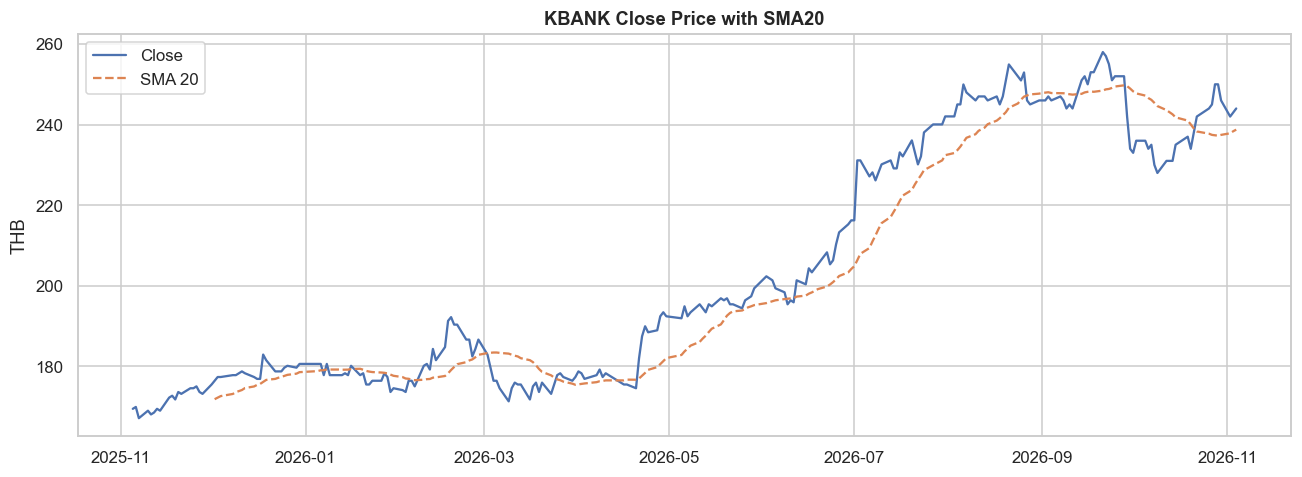

In [17]:
# matplotlib: กราฟเส้นราคา + SMA20 ของ KBANK
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df.index, df["Close"], label="Close", lw=1.5)               # เส้นราคา
ax.plot(df.index, df["SMA20"], label="SMA 20", lw=1.5, ls="--")     # เส้นค่าเฉลี่ย 20 วัน
ax.set_title("KBANK Close Price with SMA20", fontweight="bold")
ax.set_ylabel("THB"); ax.legend()
plt.tight_layout(); plt.show()

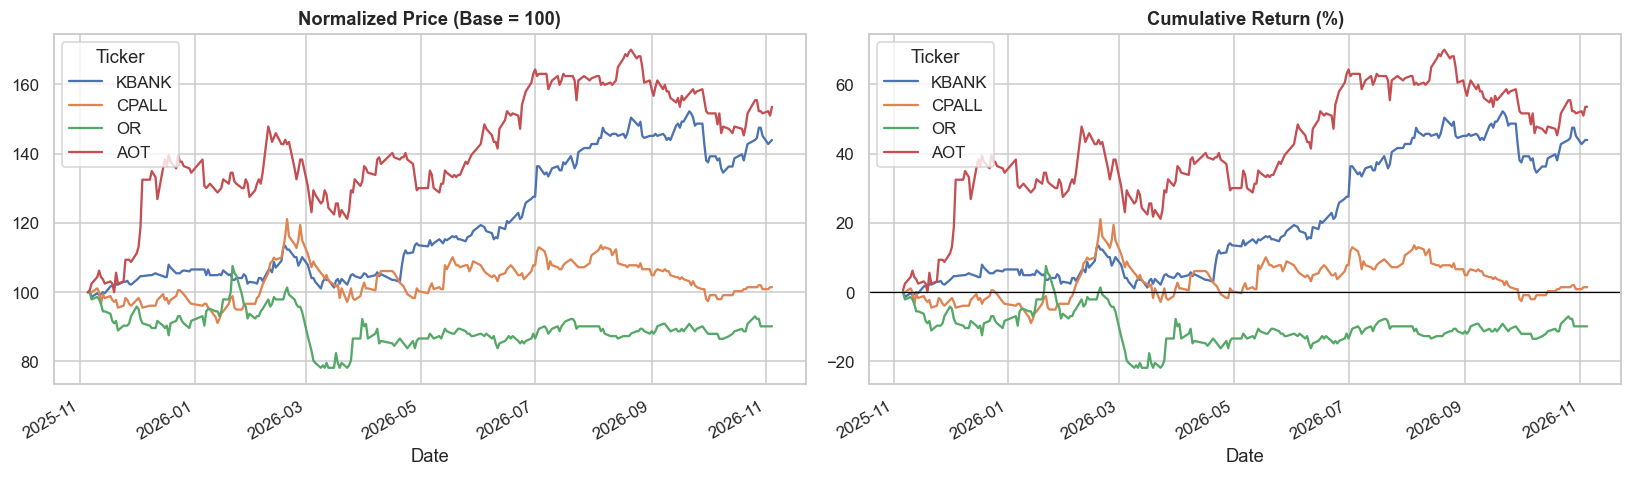

In [18]:
# matplotlib subplots: ราคาปรับฐาน 100 + ผลตอบแทนสะสมของทั้ง 4 ตัว
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
(close / close.iloc[0] * 100).plot(ax=axes[0])                      # ปรับฐานเริ่มต้น = 100
axes[0].set_title("Normalized Price (Base = 100)", fontweight="bold")
((1 + ret).cumprod() - 1).mul(100).plot(ax=axes[1])                 # ผลตอบแทนสะสม %
axes[1].set_title("Cumulative Return (%)", fontweight="bold"); axes[1].axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()

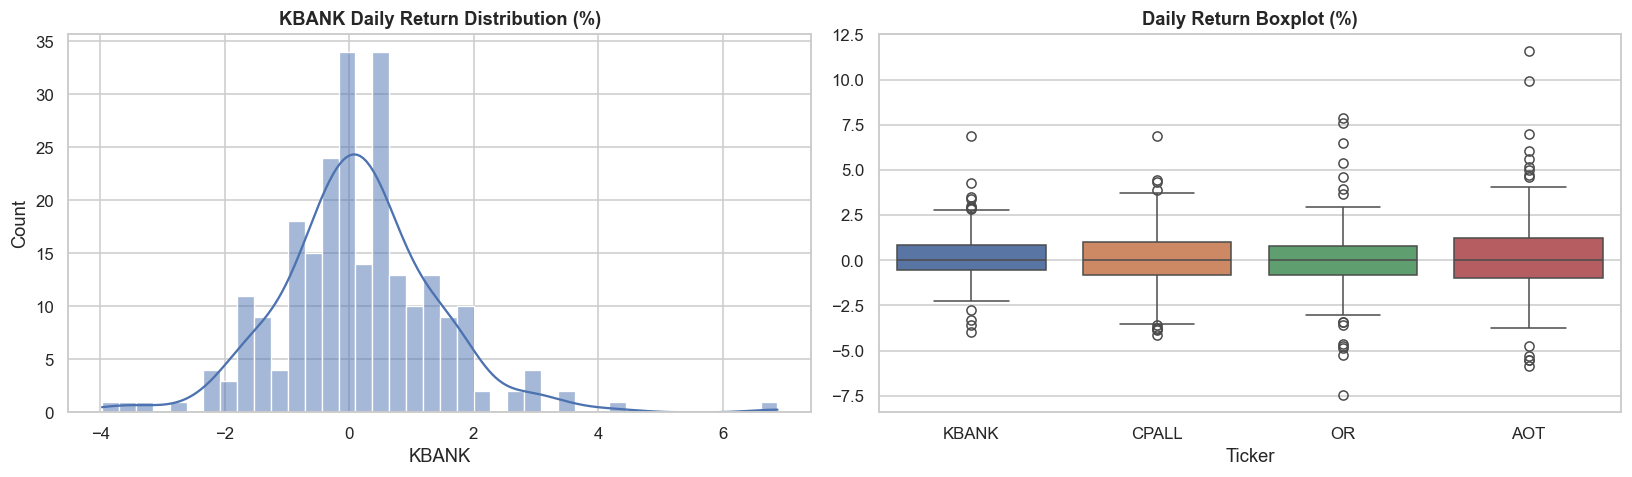

In [19]:
# seaborn: histogram ของผลตอบแทนรายวัน และ boxplot เทียบหุ้น
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(ret["KBANK"] * 100, bins=40, kde=True, ax=axes[0])      # histogram + เส้น KDE
axes[0].set_title("KBANK Daily Return Distribution (%)", fontweight="bold")
sns.boxplot(data=ret * 100, ax=axes[1])                              # กล่องแสดงการกระจาย + outlier
axes[1].set_title("Daily Return Boxplot (%)", fontweight="bold")
plt.tight_layout(); plt.show()

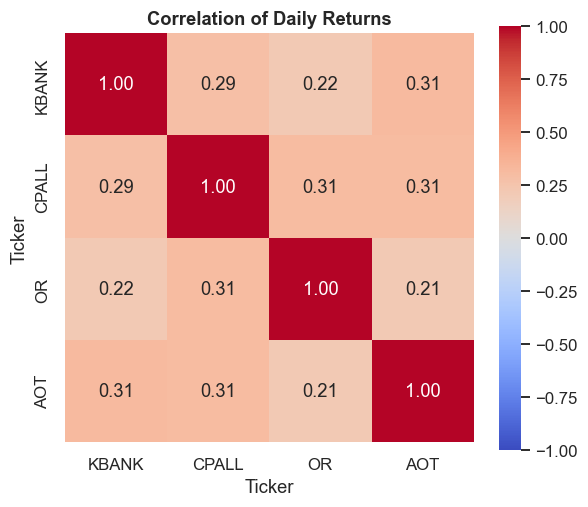

In [20]:
# seaborn: heatmap correlation ของผลตอบแทน
plt.figure(figsize=(6, 5))
sns.heatmap(ret.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)   # ใส่ตัวเลขในช่อง
plt.title("Correlation of Daily Returns", fontweight="bold"); plt.show()

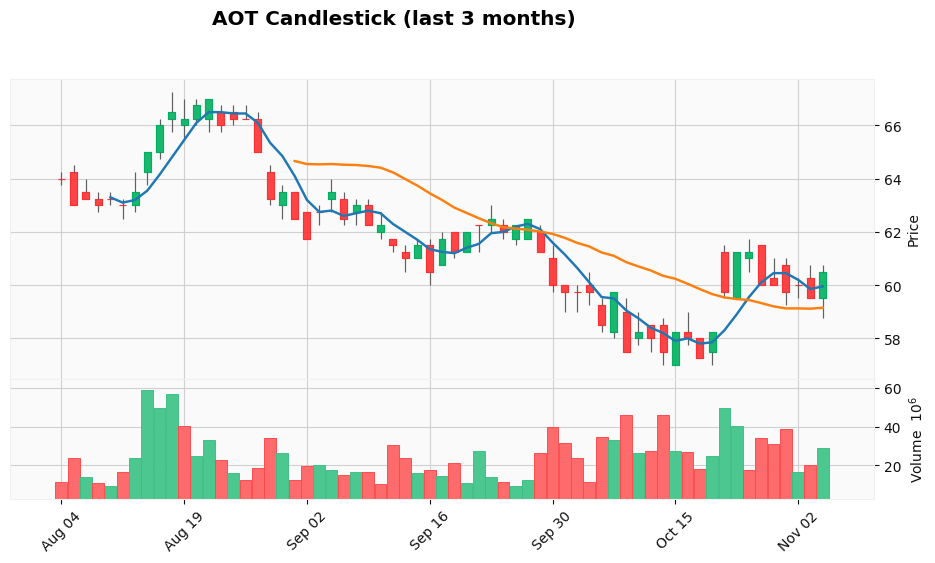

In [21]:
# mplfinance: กราฟแท่งเทียน 3 เดือนล่าสุดของ AOT พร้อม volume และเส้นค่าเฉลี่ย 5, 20 วัน
ohlc = pd.DataFrame({c: raw[c]["AOT.BK"] for c in ["Open", "High", "Low", "Close", "Volume"]}).dropna()   # จัดรูปแบบ OHLCV
mpf.plot(ohlc.tail(63), type="candle", style="yahoo", volume=True, mav=(5, 20),
         title="AOT Candlestick (last 3 months)", figsize=(12, 6))    # 63 วัน ≈ 3 เดือน

### สรุปส่วนที่ 1
- **NumPy** เหมาะกับการคำนวณเชิงตัวเลขเร็ว ๆ เช่น ผลตอบแทน, matrix covariance, น้ำหนักพอร์ต
- **Pandas** ทำให้จัดการข้อมูลที่มีวันที่เป็น index ได้สะดวก (rolling, resample, join, groupby)
- **matplotlib / seaborn / mplfinance** ใช้สื่อสารผลลัพธ์: กราฟเส้น, การกระจาย, heatmap และแท่งเทียน